In [81]:
import torch
import numpy as np
import math
import matplotlib.pyplot as plt
import seaborn as sns
import torch.nn.functional as F

In [2]:
words = open('names.txt','r').read().splitlines()
words[:10]

['emma',
 'olivia',
 'ava',
 'isabella',
 'sophia',
 'charlotte',
 'mia',
 'amelia',
 'harper',
 'evelyn']

1. biagram model is for example we have  some character at a time  and we just consider single charater to predict next  characte 
2. tiagram is similarly we consider two previos character to predict third one 
3. similarly N-gram model



In [3]:
b={}
for w in words:
    chr = ["<S>"] +list(w) +["<E>"]
    for ch1 ,ch2 in zip(chr,chr[1:]):
        bigram = (ch1,ch2)
        b[bigram] = b.get(bigram ,0)+1
# print(b)

(sorted(b.items() ,key = lambda kv : -kv[1]))
    


[(('n', '<E>'), 6763),
 (('a', '<E>'), 6640),
 (('a', 'n'), 5438),
 (('<S>', 'a'), 4410),
 (('e', '<E>'), 3983),
 (('a', 'r'), 3264),
 (('e', 'l'), 3248),
 (('r', 'i'), 3033),
 (('n', 'a'), 2977),
 (('<S>', 'k'), 2963),
 (('l', 'e'), 2921),
 (('e', 'n'), 2675),
 (('l', 'a'), 2623),
 (('m', 'a'), 2590),
 (('<S>', 'm'), 2538),
 (('a', 'l'), 2528),
 (('i', '<E>'), 2489),
 (('l', 'i'), 2480),
 (('i', 'a'), 2445),
 (('<S>', 'j'), 2422),
 (('o', 'n'), 2411),
 (('h', '<E>'), 2409),
 (('r', 'a'), 2356),
 (('a', 'h'), 2332),
 (('h', 'a'), 2244),
 (('y', 'a'), 2143),
 (('i', 'n'), 2126),
 (('<S>', 's'), 2055),
 (('a', 'y'), 2050),
 (('y', '<E>'), 2007),
 (('e', 'r'), 1958),
 (('n', 'n'), 1906),
 (('y', 'n'), 1826),
 (('k', 'a'), 1731),
 (('n', 'i'), 1725),
 (('r', 'e'), 1697),
 (('<S>', 'd'), 1690),
 (('i', 'e'), 1653),
 (('a', 'i'), 1650),
 (('<S>', 'r'), 1639),
 (('a', 'm'), 1634),
 (('l', 'y'), 1588),
 (('<S>', 'l'), 1572),
 (('<S>', 'c'), 1542),
 (('<S>', 'e'), 1531),
 (('j', 'a'), 1473),
 (

In [4]:
N = torch.zeros((27,27),dtype=torch.int32)

In [5]:
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for (i,s) in enumerate(chars)}
stoi["."]=0

stoi


for w in words:
    chr = ["."] +list(w) +["."]
    for ch1 ,ch2 in zip(chr,chr[1:]):
        idx1 = stoi[ch1]
        idx2 = stoi[ch2]
        N[idx1,idx2]+=1
itos = {i:s for s,i in stoi.items()}

In [6]:
print(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


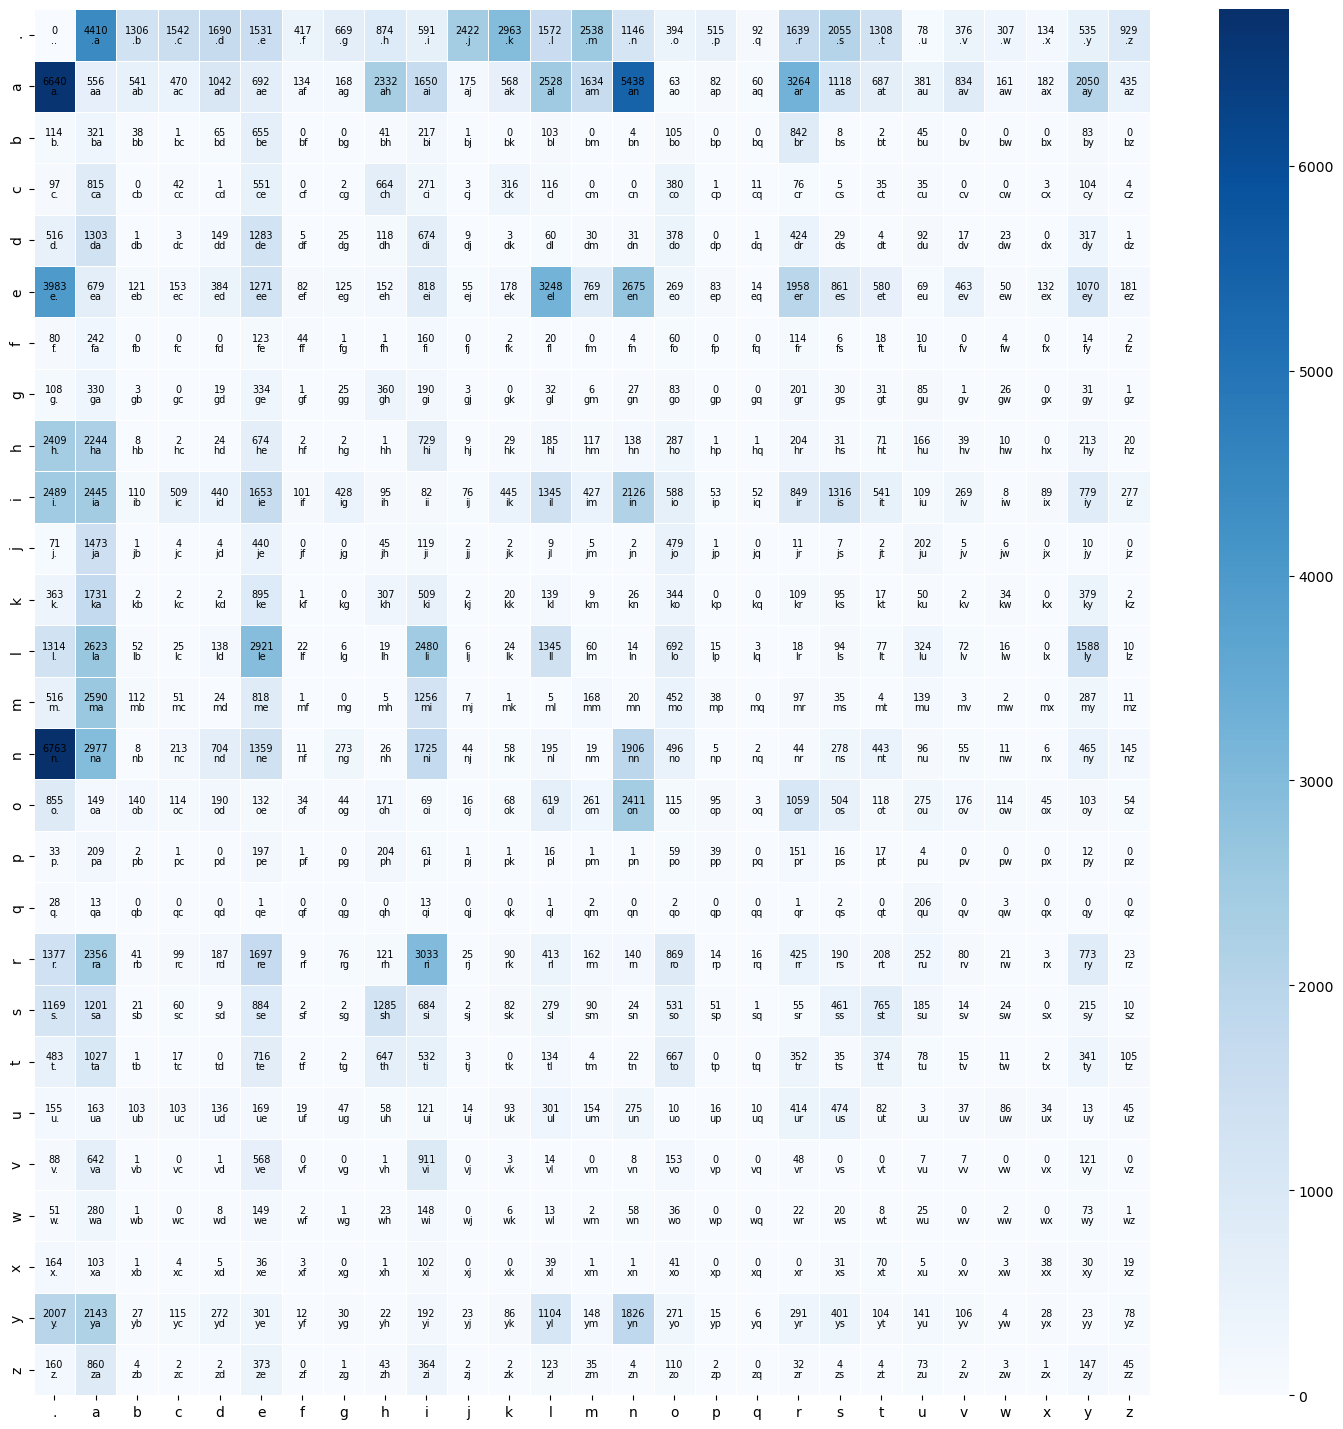

In [7]:

chars = [itos[i] for i in range(27)]

fig, ax = plt.subplots(figsize=(18, 18))
sns.heatmap(N, 
            xticklabels=chars, 
            yticklabels=chars,
            cmap='Blues',
            ax=ax,
            linewidths=0.5,
            annot=False)  

for i in range(27):
    for j in range(27):
        ax.text(j + 0.5, i + 0.5, 
                f'{itos[i]}{itos[j]}',   # the bigram label
                ha='center', va='top', 
                fontsize=7, color='black')
        ax.text(j + 0.5, i + 0.5, 
                str(int(N[i, j])),        # the count below it
                ha='center', va='bottom', 
                fontsize=7, color='black')

plt.show()

convert to probability

In [8]:
p=N[0]
p=p/p.sum()
p

tensor([0.0000, 0.1377, 0.0408, 0.0481, 0.0528, 0.0478, 0.0130, 0.0209, 0.0273,
        0.0184, 0.0756, 0.0925, 0.0491, 0.0792, 0.0358, 0.0123, 0.0161, 0.0029,
        0.0512, 0.0642, 0.0408, 0.0024, 0.0117, 0.0096, 0.0042, 0.0167, 0.0290])

pytorch genertor to get sample based on probability of each

In [10]:
g = torch.Generator().manual_seed(2147483647)
ix = torch.multinomial(p,num_samples=20,generator=g,replacement=True)
ix
chars_sample = [itos[i.item()] for i in ix]
print(chars_sample)

['m', 's', 'n', 'a', 'a', 't', 't', 'a', 'm', 'm', 'm', 'k', 'w', 'm', 's', 'r', 'z', 'k', 'g', 's']


always respect broadcasting in tensor 
1. keepdim bug

model_smoothening by add 1

In [61]:
P =(N+1).float()
# X =N.float()
# P.sum(dim=1)
# print(P.sum(dim=1 ).shape)
# print(X.sum(dim=0,keepdim=True).shape)
P /= P.sum(dim=1 ,keepdim=True)
# X =X/X.sum(dim=1,keepdim=True)
# print(X[0])
print(P[0])

tensor([3.1192e-05, 1.3759e-01, 4.0767e-02, 4.8129e-02, 5.2745e-02, 4.7785e-02,
        1.3038e-02, 2.0898e-02, 2.7293e-02, 1.8465e-02, 7.5577e-02, 9.2452e-02,
        4.9064e-02, 7.9195e-02, 3.5777e-02, 1.2321e-02, 1.6095e-02, 2.9008e-03,
        5.1154e-02, 6.4130e-02, 4.0830e-02, 2.4641e-03, 1.1759e-02, 9.6070e-03,
        4.2109e-03, 1.6719e-02, 2.9008e-02])


In [62]:
ix =0
for i in range(5):
    out =[]
    while True:
        # p= N[ix].float()
        # p =p/p.sum()
        # p = torch.ones(27)/27
        p= P[ix]
        ix = torch.multinomial(p,num_samples=1,generator=g,replacement=True).item()
        out.append(itos[ix])
        if ix == 0:
            break
    print(''.join(out))
        
    
        

cyace.
le.
lessamyet.
awewenae.
wnifaydeir.


In [74]:
log_likelihood =0
n=0

for w in words[:3]:
    chr = ["."] +list(w) +["."]
    for ch1 ,ch2 in zip(chr,chr[1:]):
        idx1 = stoi[ch1]
        idx2 = stoi[ch2]
        prob = P[idx1,idx2]
        logprob = torch.log(prob)
        log_likelihood += logprob
        n+=1
        # print(f'{ch1}{ch2} {prob}')
print(f'{log_likelihood}')
print(f'{-log_likelihood/n}')


-38.80856704711914
2.4255354404449463


In [212]:
xs ,ys =[], []
for w in words:
    each_word_xs =[]
    chr = ["."] +list(w) +["."]
    for ch1 ,ch2 in zip(chr,chr[1:]):
        idx1 = stoi[ch1]
        idx2 = stoi[ch2]
        xs.append(idx1)
        ys.append(idx2)

xs = torch.tensor(xs)
ys = torch.tensor(ys)
xs.shape
num =xs.nelement()
print(num)

228146


In [213]:
ys.shape

torch.Size([228146])

In [214]:
g= torch.Generator().manual_seed(2147483647)
w = torch.randn((27,27),generator=g,requires_grad=True)
w.shape

torch.Size([27, 27])

one hot encoding to each index 

In [215]:
xenc  = F.one_hot(xs ,num_classes=27).float()

# print(xenc)
xenc.shape

torch.Size([228146, 27])

In [216]:
for i in range(100):
    logits  = xenc @ w
    counts = logits.exp()
    # print(counts)
    probs = counts/counts.sum(1, keepdim=True) #softmax
    probs.shape
    loss = -probs[torch.arange(xs.shape[0]),ys].log().mean()
    print(f'epochs :{i} ,loss :{loss}')
    #backward pass
    w.grad =None
    loss.backward()
    w.data += (-10)* w.grad

epochs :0 ,loss :3.758953332901001
epochs :1 ,loss :3.6702592372894287
epochs :2 ,loss :3.591153860092163
epochs :3 ,loss :3.520017385482788
epochs :4 ,loss :3.4557948112487793
epochs :5 ,loss :3.397716522216797
epochs :6 ,loss :3.345163583755493
epochs :7 ,loss :3.2975902557373047
epochs :8 ,loss :3.254483938217163
epochs :9 ,loss :3.2153544425964355
epochs :10 ,loss :3.17973256111145
epochs :11 ,loss :3.147189140319824
epochs :12 ,loss :3.117339849472046
epochs :13 ,loss :3.0898516178131104
epochs :14 ,loss :3.064443349838257
epochs :15 ,loss :3.0408785343170166
epochs :16 ,loss :3.0189592838287354
epochs :17 ,loss :2.998518943786621
epochs :18 ,loss :2.9794163703918457
epochs :19 ,loss :2.9615297317504883
epochs :20 ,loss :2.9447529315948486
epochs :21 ,loss :2.928992509841919
epochs :22 ,loss :2.9141645431518555
epochs :23 ,loss :2.900193929672241
epochs :24 ,loss :2.887012243270874
epochs :25 ,loss :2.874558925628662
epochs :26 ,loss :2.8627758026123047
epochs :27 ,loss :2.8516137